# Mental Health Statement Classification






## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import re
import nltk
import spacy
from wordcloud import WordCloud
from nltk.corpus import stopwords

In [5]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score,
    precision_recall_fscore_support,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [7]:
nltk.download('stopwords', quiet=True)
print(f'TensorFlow {tf.__version__}')

TensorFlow 2.21.0


## Load the Data

In [8]:
df = pd.read_csv('Combined Data.csv')
df.head()

,Unnamed: 0,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,3,I've shifted my focus to something else but I'...,Anxiety
4,4,"I'm restless and restless, it's been a month n...",Anxiety


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53043 entries, 0 to 53042
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  53043 non-null  int64
 1   statement   52681 non-null  str  
 2   status      53043 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.2 MB


In [10]:
df.describe()

,Unnamed: 0
count,53043.000000
mean,26521.000000
std,15312.339501
min,0.000000
25%,13260.500000
50%,26521.000000
75%,39781.500000
max,53042.000000


In [11]:
# Droping the unnamed index column 
df.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

In [12]:
# Checking for missing values before dropping them
df.isnull().sum()


statement    362
status         0
dtype: int64

In [13]:
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Shape after dropping NaN: {df.shape}')

Shape after dropping NaN: (52681, 2)


In [14]:
# Looking  at the unique class labels
df['status'].unique()

<StringArray>
[             'Anxiety',               'Normal',           'Depression',
             'Suicidal',               'Stress',              'Bipolar',
 'Personality disorder']
Length: 7, dtype: str

## Exploratory Data Analysis

### Class Distribution

In [15]:
#checking  how balanced the classes are
label_counts = df['status'].value_counts()
print(label_counts)

status
Normal                  16343
Depression              15404
Suicidal                10652
Anxiety                  3841
Bipolar                  2777
Stress                   2587
Personality disorder     1077
Name: count, dtype: int64


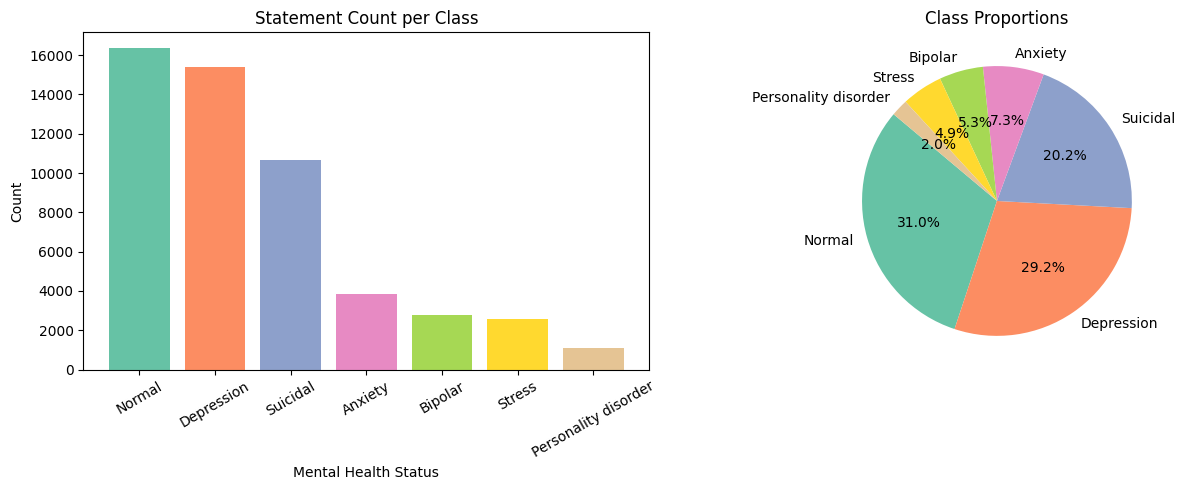

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart of raw counts
axes[0].bar(label_counts.index, label_counts.values,
            color=sns.color_palette('Set2', len(label_counts)))
axes[0].set_title('Statement Count per Class')
axes[0].set_xlabel('Mental Health Status')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

# Pie chart of proportions
axes[1].pie(label_counts.values,
            labels=label_counts.index,
            autopct='%1.1f%%',
            colors=sns.color_palette('Set2', len(label_counts)),
            startangle=140)
axes[1].set_title('Class Proportions')

plt.tight_layout()
plt.show()

The dataset is moderately imbalanced Normal and Depression together make up around 60% of samples.

### Statement Length

In [17]:
# I am looking at how long the statements are so I can choose a good sequence length for my deep learning model
df['text_length'] = df['statement'].apply(lambda x: len(str(x).split()))
df['text_length'].describe()

count    52681.000000
mean       113.158729
std        163.735305
min          1.000000
25%         15.000000
50%         62.000000
75%        148.000000
max       6300.000000
Name: text_length, dtype: float64

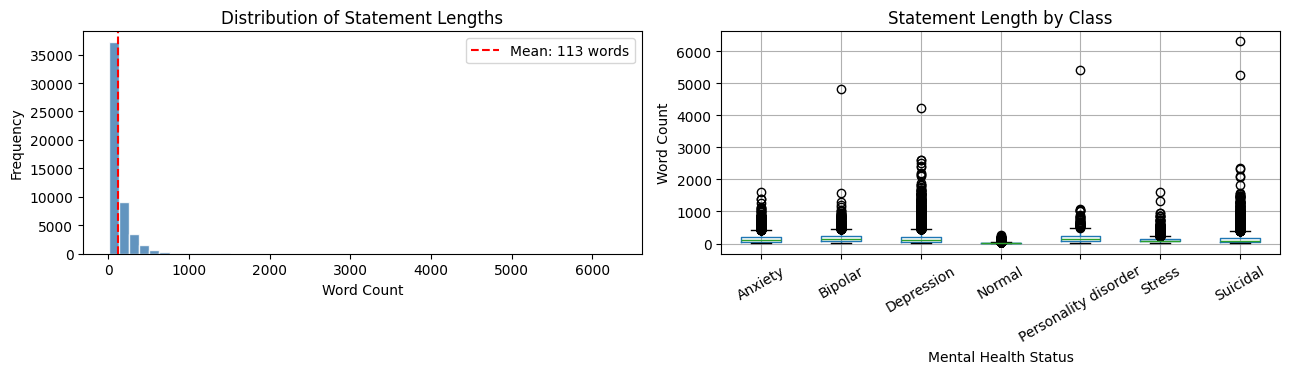

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram of lengths across all classes
axes[0].hist(df['text_length'], bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df['text_length'].mean(), color='red', linestyle='--',
                label=f'Mean: {df["text_length"].mean():.0f} words')
axes[0].set_title('Distribution of Statement Lengths')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Box plot per class to see if length varies by diagnosis
df.boxplot(column='text_length', by='status', ax=axes[1])
axes[1].set_title('Statement Length by Class')
axes[1].set_xlabel('Mental Health Status')
axes[1].set_ylabel('Word Count')
plt.suptitle('')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Word Clouds

In [19]:
#  generating word clouds 
def plot_wordcloud(text, title, ax):
    

    wc = WordCloud(
        width=500, height=280,
        background_color='white',
        colormap='Blues',
        max_words=80,
        contour_width=2,
        contour_color='steelblue'
    ).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=11, fontweight='bold')

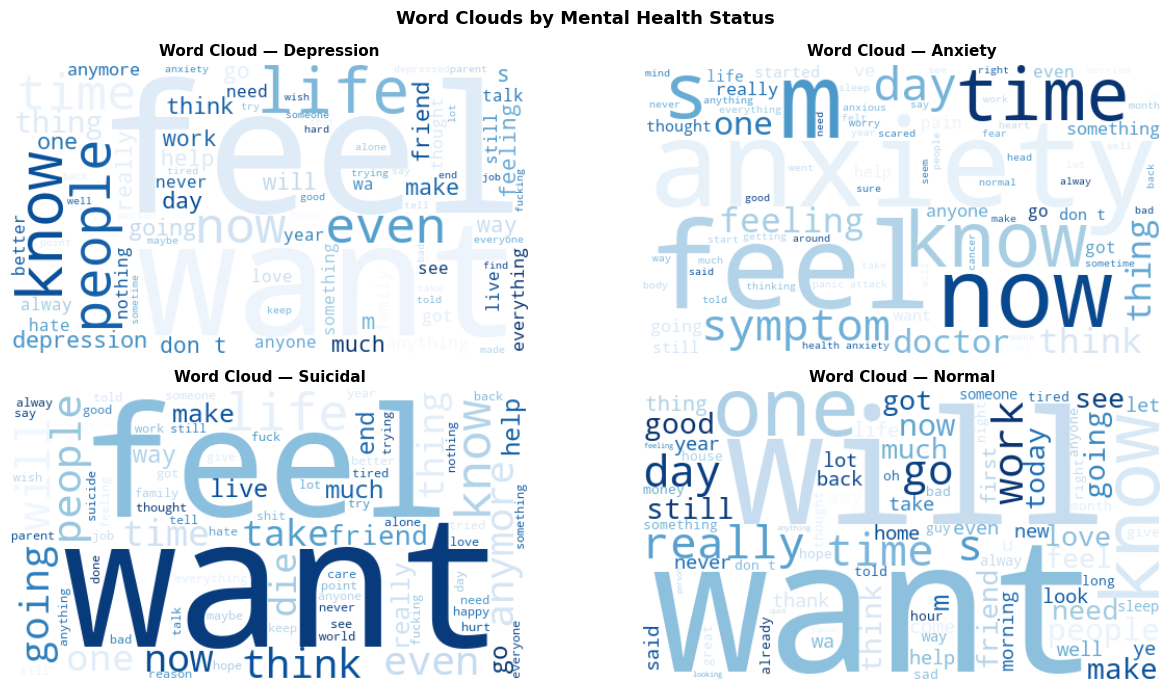

In [20]:
selected_classes = ['Depression', 'Anxiety', 'Suicidal', 'Normal']
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes = axes.flatten()

for i, cls in enumerate(selected_classes):
    # Join all statements for this class into one big string
    text = ' '.join(df[df['status'] == cls]['statement'].astype(str).values)
    plot_wordcloud(text, f'Word Cloud — {cls}', axes[i])

plt.suptitle('Word Clouds by Mental Health Status', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Correlation Heatmap — Class vs Length

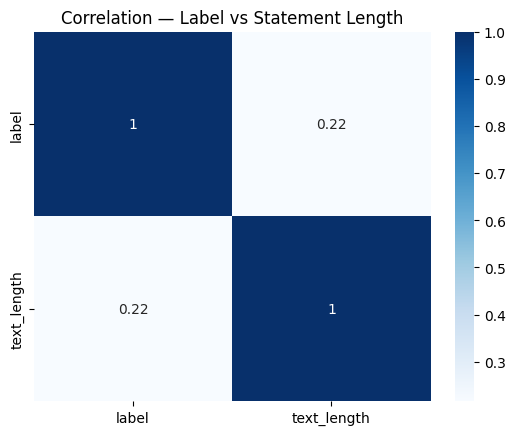

In [21]:
# Encode labels numerically to check correlations
label_mapping = {
    'Anxiety': 0, 'Normal': 1, 'Depression': 2,
    'Suicidal': 3, 'Stress': 4, 'Bipolar': 5, 'Personality disorder': 6
}
int_to_label = {v: k for k, v in label_mapping.items()}
num_classes   = len(label_mapping)

df['label'] = df['status'].map(label_mapping)

# Show correlation between label and text length
sns.heatmap(df[['label', 'text_length']].corr(), annot=True, cmap='Blues')
plt.title('Correlation — Label vs Statement Length')
plt.show()

## Text Preprocessing


### Cleaning

In [22]:
def clean_text(series):

    text = series.str.lower()
    text = text.str.replace(r'https?://\S+|www\.\S+', '', regex=True)   # remove URLs
    text = text.str.replace(r'<.*?>', '', regex=True)                    # remove HTML tags
    text = text.str.replace(r'[^\w\s]', '', regex=True)                  # remove punctuation
    text = text.str.replace(r'\d+', '', regex=True)                      # remove digits
    text = text.str.replace(r'\s+', ' ', regex=True).str.strip()         # collapse whitespace
    return text

In [23]:
df['clean'] = clean_text(df['statement'])
df[['statement', 'clean']].head(3)

,statement,clean
0,oh my gosh,oh my gosh
1,"trouble sleeping, confused mind, restless hear...",trouble sleeping confused mind restless heart ...
2,"All wrong, back off dear, forward doubt. Stay ...",all wrong back off dear forward doubt stay in ...


### Stopword Removal

In [24]:
def remove_stopwords(series):

    stop_words = set(stopwords.words('english'))
    return series.apply(
        lambda x: ' '.join(w for w in x.split() if w not in stop_words)
    )

In [25]:
df['clean'] = remove_stopwords(df['clean'])

### Lemmatisation

In [26]:
import subprocess, sys

# Downloading the spaCy English model if it is not already installed
try:
    spacy.load("en_core_web_sm")
except OSError:
    print("Downloading en_core_web_sm...")
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
    print("Done.")

In [27]:
# Initialize spaCy model — disable components we don't need for efficiency
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

In [28]:
def lemmatize_text(text):
   
    doc = nlp(text)
    return ' '.join(token.lemma_ for token in doc)

In [29]:
print('Lemmatising — this may take a few minutes...')
df['processed'] = df['clean'].apply(lemmatize_text)
print('Done.')

Lemmatising — this may take a few minutes...
Done.


In [30]:
df[['statement', 'processed']].head(5)

,statement,processed
0,oh my gosh,oh gosh
1,"trouble sleeping, confused mind, restless hear...",trouble sleep confused mind restless heart tune
2,"All wrong, back off dear, forward doubt. Stay ...",wrong back dear forward doubt stay restless re...
3,I've shifted my focus to something else but I'...,I ve shift focus something else I m still worried
4,"I'm restless and restless, it's been a month n...",I m restless restless month boy mean


## Train / Test Split

Use a stratified split to preserve class proportions in both training and test sets

In [31]:
X = df['processed']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,   # 75% train, 25% test
    random_state=42,
    stratify=y        # preserve class ratios
)

print(f'Training samples : {len(X_train)}')
print(f'Test samples     : {len(X_test)}')

Training samples : 39510
Test samples     : 13171


In [32]:
y_train.map(int_to_label).value_counts()

label
Normal                  12257
Depression              11553
Suicidal                 7989
Anxiety                  2880
Bipolar                  2083
Stress                   1940
Personality disorder      808
Name: count, dtype: int64

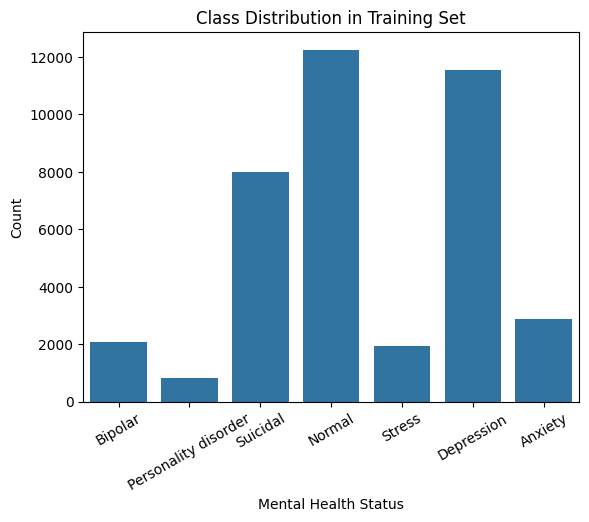

In [33]:
sns.countplot(x=y_train.map(int_to_label))
plt.title('Class Distribution in Training Set')
plt.xlabel('Mental Health Status')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.show()

## Metrics Helper


In [34]:
df_list_metrics = []

In [35]:
def return_metrics(name, y_pred, y_true):
    """
    Return evaluation metrics for a classifier as a dataframe row.

    Parameters
    ----------
    name   : str          — model name
    y_pred : array-like   — predicted labels
    y_true : array-like   — true labels

    Returns
    -------
    pd.DataFrame with accuracy and weighted F1
    """
    df_metrics = pd.DataFrame()
    accuracy   = accuracy_score(y_true, y_pred)
    f1         = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    df_metrics['Model']       = [name]
    df_metrics['Accuracy']    = [round(accuracy, 4)]
    df_metrics['Weighted F1'] = [round(f1, 4)]
    return df_metrics

## Majority Class Baseline



In [36]:
class MajorityBaseline():
  

    def __init__(self):
        self.mode = None

    def fit(self, X, y):
        # Storing the most common class label
        self.mode = y.mode()[0]

    def predict(self, X):
        #  return the majority class
        return np.ones(len(X), dtype=int) * self.mode

In [37]:
baseline = MajorityBaseline()
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

print(f'Majority class : {int_to_label[baseline.mode]}')
print(f'Accuracy       : {accuracy_score(y_test, y_pred_baseline):.4f}')
print(f'Weighted F1    : {f1_score(y_test, y_pred_baseline, average="weighted", zero_division=0):.4f}')

Majority class : Normal
Accuracy       : 0.3102
Weighted F1    : 0.1469


In [38]:
df_list_metrics.append(return_metrics('Majority Baseline', y_pred_baseline, y_test))

## Traditional Machine Learning


### Naïve Bayes



In [39]:
from sklearn.feature_extraction.text import TfidfTransformer

In [40]:
# Pipeline: vectorise → TF-IDF weight → classify
nb_pipeline = Pipeline([
    ('vect',  CountVectorizer(max_features=20000, ngram_range=(1, 2), max_df=0.95, min_df=2)),
    ('tfidf', TfidfTransformer()),
    ('clf',   MultinomialNB(alpha=0.1))
])

In [41]:
nb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vect', ...), ('tfidf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [42]:
y_pred_nb = nb_pipeline.predict(X_test)

In [43]:
print(classification_report(y_test, y_pred_nb,
                             target_names=[int_to_label[i] for i in range(num_classes)]))

                      precision    recall  f1-score   support

             Anxiety       0.74      0.70      0.72       961
              Normal       0.87      0.82      0.84      4086
          Depression       0.57      0.76      0.65      3851
            Suicidal       0.66      0.59      0.62      2663
              Stress       0.71      0.28      0.41       647
             Bipolar       0.78      0.62      0.69       694
Personality disorder       0.91      0.35      0.51       269

            accuracy                           0.70     13171
           macro avg       0.75      0.59      0.63     13171
        weighted avg       0.72      0.70      0.70     13171



In [44]:
def plot_cm(y_true, y_pred, title):

    labels = [int_to_label[i] for i in range(num_classes)]
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

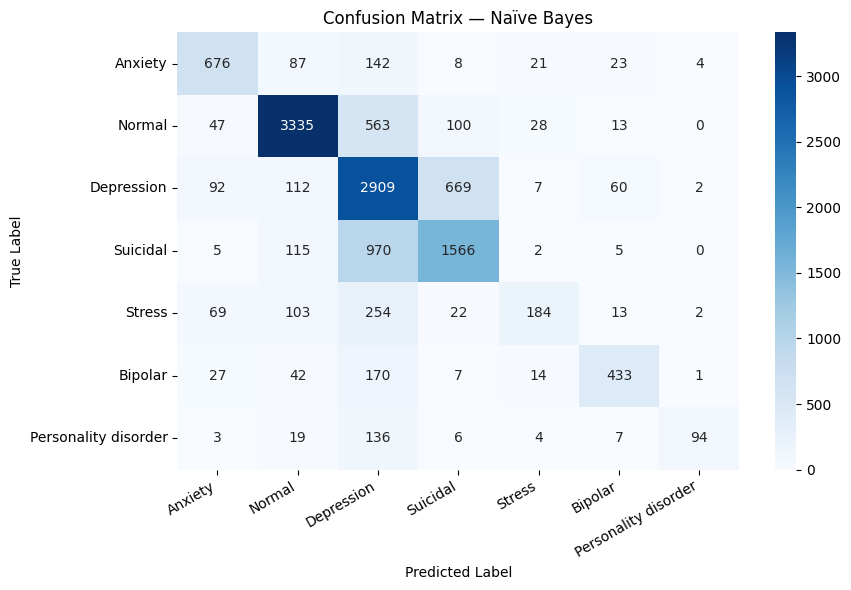

In [45]:
plot_cm(y_test, y_pred_nb, 'Confusion Matrix — Naïve Bayes')

In [46]:
# Tune alpha — the Laplace smoothing parameter
nb_param_grid = {'clf__alpha': [0.01, 0.05, 0.1, 0.5, 1.0]}

nb_gs = GridSearchCV(
    nb_pipeline, nb_param_grid,
    cv=5, scoring='f1_weighted', n_jobs=-1, verbose=1
)
nb_gs.fit(X_train, y_train)

print(f'Best alpha : {nb_gs.best_params_}')
print(f'Best CV F1 : {nb_gs.best_score_:.4f}')

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best alpha : {'clf__alpha': 0.05}
Best CV F1 : 0.6966


In [47]:
y_pred_nb_tuned = nb_gs.predict(X_test)
print(classification_report(y_test, y_pred_nb_tuned,
                             target_names=[int_to_label[i] for i in range(num_classes)]))

                      precision    recall  f1-score   support

             Anxiety       0.73      0.70      0.72       961
              Normal       0.89      0.80      0.84      4086
          Depression       0.56      0.76      0.65      3851
            Suicidal       0.66      0.59      0.62      2663
              Stress       0.70      0.31      0.43       647
             Bipolar       0.79      0.63      0.70       694
Personality disorder       0.91      0.39      0.55       269

            accuracy                           0.70     13171
           macro avg       0.75      0.60      0.64     13171
        weighted avg       0.72      0.70      0.70     13171



In [48]:
df_list_metrics.append(return_metrics('Naïve Bayes (tuned)', y_pred_nb_tuned, y_test))

### Logistic Regression



In [49]:
lr_pipeline = Pipeline([
    ('vect', CountVectorizer(max_features=20000, ngram_range=(1, 2), max_df=0.95, min_df=2)),
    ('tfidf', TfidfTransformer()),
    ('clf',  LogisticRegression(
        max_iter=1000,
        C=5.0,
        class_weight='balanced',
        solver='lbfgs',
        random_state=42
    ))
])

In [50]:
lr_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vect', ...), ('tfidf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [51]:
y_pred_lr = lr_pipeline.predict(X_test)

In [52]:
print(classification_report(y_test, y_pred_lr,
                             target_names=[int_to_label[i] for i in range(num_classes)]))

                      precision    recall  f1-score   support

             Anxiety       0.77      0.82      0.79       961
              Normal       0.89      0.91      0.90      4086
          Depression       0.73      0.64      0.69      3851
            Suicidal       0.64      0.67      0.65      2663
              Stress       0.55      0.64      0.59       647
             Bipolar       0.79      0.80      0.80       694
Personality disorder       0.64      0.70      0.67       269

            accuracy                           0.76     13171
           macro avg       0.72      0.74      0.73     13171
        weighted avg       0.76      0.76      0.76     13171



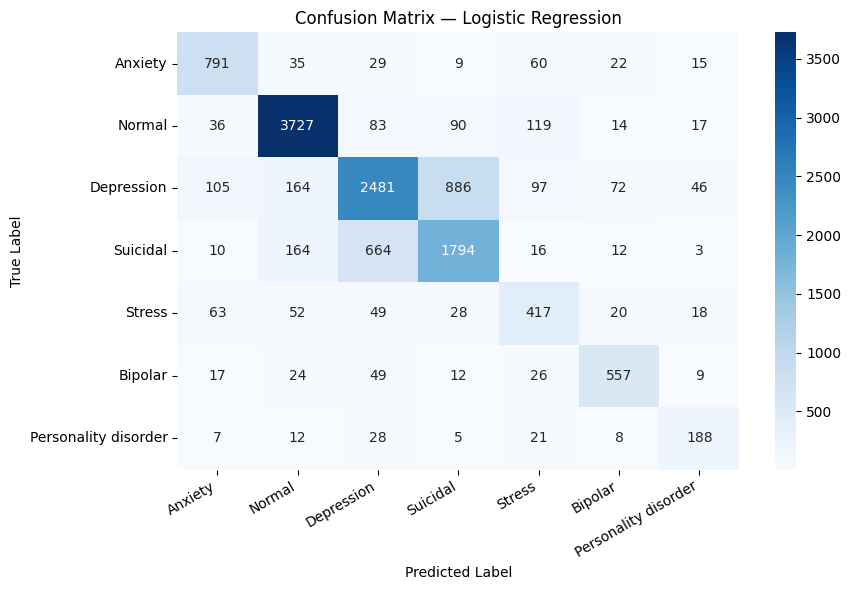

In [53]:
plot_cm(y_test, y_pred_lr, 'Confusion Matrix — Logistic Regression')

In [54]:
# Tune C — the inverse of regularisation strength. Smaller = stronger regularisation
lr_param_grid = {'clf__C': [0.1, 1.0, 5.0, 10.0]}

lr_gs = GridSearchCV(
    lr_pipeline, lr_param_grid,
    cv=5, scoring='f1_weighted', n_jobs=-1, verbose=1
)
lr_gs.fit(X_train, y_train)

print(f'Best C     : {lr_gs.best_params_}')
print(f'Best CV F1 : {lr_gs.best_score_:.4f}')

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best C     : {'clf__C': 5.0}
Best CV F1 : 0.7608


In [55]:
y_pred_lr_tuned = lr_gs.predict(X_test)
print(classification_report(y_test, y_pred_lr_tuned,
                             target_names=[int_to_label[i] for i in range(num_classes)]))

                      precision    recall  f1-score   support

             Anxiety       0.77      0.82      0.79       961
              Normal       0.89      0.91      0.90      4086
          Depression       0.73      0.64      0.69      3851
            Suicidal       0.64      0.67      0.65      2663
              Stress       0.55      0.64      0.59       647
             Bipolar       0.79      0.80      0.80       694
Personality disorder       0.64      0.70      0.67       269

            accuracy                           0.76     13171
           macro avg       0.72      0.74      0.73     13171
        weighted avg       0.76      0.76      0.76     13171



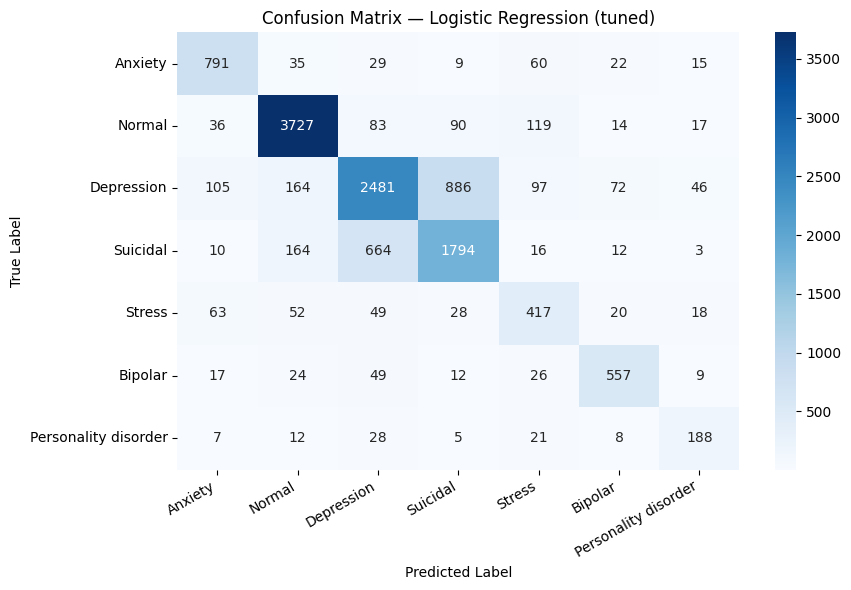

In [56]:
plot_cm(y_test, y_pred_lr_tuned, 'Confusion Matrix — Logistic Regression (tuned)')

In [57]:
df_list_metrics.append(return_metrics('Logistic Regression (tuned)', y_pred_lr_tuned, y_test))

In [58]:
pd.concat(df_list_metrics)

,Model,Accuracy,Weighted F1
0,Majority Baseline,0.3102,0.1469
0,Naïve Bayes (tuned),0.6976,0.6970
0,Logistic Regression (tuned),0.7558,0.7553


## Deep Learning — Tokenisation



In [59]:
# Hyperparameters for the deep learning models
VOCAB_SIZE  = 30000   # vocabulary size — covers most words in the dataset
MAX_LEN     = 200     # sequence length — 95th percentile of statement lengths
EMBED_DIM   = 128     # embedding dimension
BATCH_SIZE  = 64
EPOCHS      = 10

In [60]:
# Fit the tokeniser on training text only
tokenizer_dl = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer_dl.fit_on_texts(X_train)
print(f'Vocabulary size: {len(tokenizer_dl.word_index):,}')

Vocabulary size: 55,946


Converting  text to integer sequences

In [61]:
X_train_seq = tokenizer_dl.texts_to_sequences(X_train)
X_test_seq  = tokenizer_dl.texts_to_sequences(X_test)

In [62]:
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad  = pad_sequences(X_test_seq,  maxlen=MAX_LEN, padding='post', truncating='post')

print(f'X_train_pad shape : {X_train_pad.shape}')
print(f'X_test_pad  shape : {X_test_pad.shape}')

X_train_pad shape : (39510, 200)
X_test_pad  shape : (13171, 200)


## Deep Learning Model 1 — Bidirectional LSTM



In [63]:
def build_bilstm(vocab_size, embed_dim, max_len, num_classes,
                  lstm_units=128, dropout=0.3):
   
    inputs = keras.Input(shape=(max_len,), dtype='int32', name='input_ids')

    # Learnable embedding layer maps integer tokens to dense vectors
    x = layers.Embedding(vocab_size, embed_dim, input_length=max_len)(inputs)

    # SpatialDropout drops entire embedding dimensions rather than individual elements
    x = layers.SpatialDropout1D(dropout)(x)

    # First BiLSTM — return sequences so the second BiLSTM can process them
    x = layers.Bidirectional(
            layers.LSTM(lstm_units, return_sequences=True,
                        dropout=dropout, recurrent_dropout=0.1)
        )(x)

    # Second BiLSTM — produces a single context vector
    x = layers.Bidirectional(
            layers.LSTM(lstm_units // 2, dropout=dropout, recurrent_dropout=0.1)
        )(x)

    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(dropout)(x)

    # Softmax output over all seven classes
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs, name='BiLSTM')

In [64]:
bilstm_model = build_bilstm(VOCAB_SIZE, EMBED_DIM, MAX_LEN, num_classes)
bilstm_model.summary()

Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)               │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 200, 128)            │       3,840,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ (None, 200, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 200, 256)            │         263,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 128)                 │         164,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,284,935 (16.35 MB)

 Trainable params: 4,284,935 (16.35 MB)

 Non-trainable params: 0 (0.00 B)

In [65]:
bilstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [66]:
callbacks_bilstm = [
    # Stop training if val_accuracy does not improve for 3 epochs
    EarlyStopping(patience=3, restore_best_weights=True, monitor='val_accuracy'),
    # Halve the learning rate if val_loss plateaus for 2 epochs
    ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

In [67]:
history_bilstm = bilstm_model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_bilstm,
    verbose=1
)

Epoch 1/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 1352s 2s/step - accuracy: 0.6011 - loss: 0.9982 - val_accuracy: 0.6669 - val_loss: 0.8182 - learning_rate: 0.0010
Epoch 2/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 1346s 2s/step - accuracy: 0.7110 - loss: 0.7345 - val_accuracy: 0.7054 - val_loss: 0.7050 - learning_rate: 0.0010
Epoch 3/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 1366s 2s/step - accuracy: 0.7644 - loss: 0.6066 - val_accuracy: 0.7494 - val_loss: 0.6427 - learning_rate: 0.0010
Epoch 4/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 1370s 2s/step - accuracy: 0.8019 - loss: 0.5201 - val_accuracy: 0.7578 - val_loss: 0.6264 - learning_rate: 0.0010
Epoch 5/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 1387s 2s/step - accuracy: 0.8321 - loss: 0.4518 - val_accuracy: 0.7423 - val_loss: 0.6524 - learning_rate: 0.0010
Epoch 6/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8539 - loss: 0.4009
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
556/556 ━━━━━━━━━━━━━━━━━━━━ 1401s 3s/step - accuracy: 0.8479 - loss:

In [68]:
# ploting  the training and validation curves to check for overfitting
def plot_history(history, title):
  
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Accuracy
    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='darkorange')
    axes[0].set_title(f'{title} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='darkorange')
    axes[1].set_title(f'{title} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

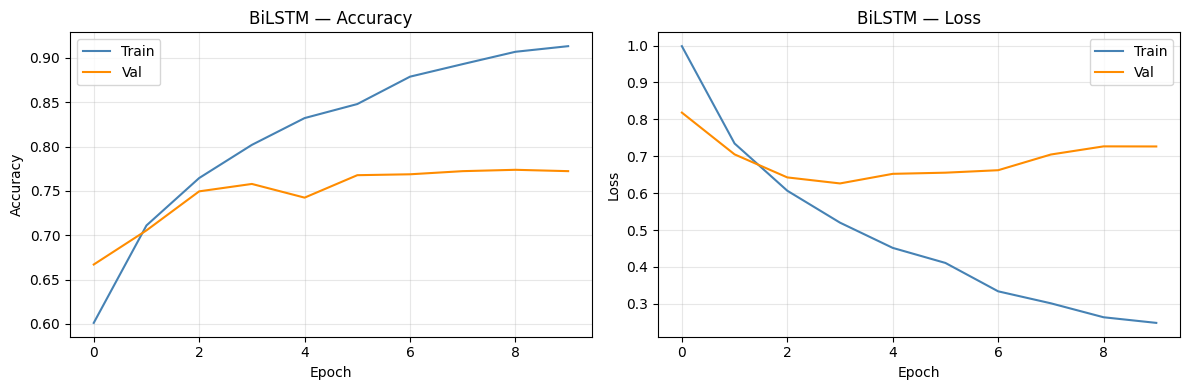

In [69]:
plot_history(history_bilstm, 'BiLSTM')

In [70]:
y_proba_bilstm = bilstm_model.predict(X_test_pad, verbose=0)
y_pred_bilstm  = np.argmax(y_proba_bilstm, axis=1)

In [71]:
print(classification_report(y_test, y_pred_bilstm,
                             target_names=[int_to_label[i] for i in range(num_classes)]))

                      precision    recall  f1-score   support

             Anxiety       0.77      0.81      0.79       961
              Normal       0.90      0.91      0.91      4086
          Depression       0.71      0.69      0.70      3851
            Suicidal       0.63      0.66      0.65      2663
              Stress       0.58      0.54      0.56       647
             Bipolar       0.89      0.77      0.82       694
Personality disorder       0.62      0.56      0.59       269

            accuracy                           0.76     13171
           macro avg       0.73      0.71      0.72     13171
        weighted avg       0.76      0.76      0.76     13171



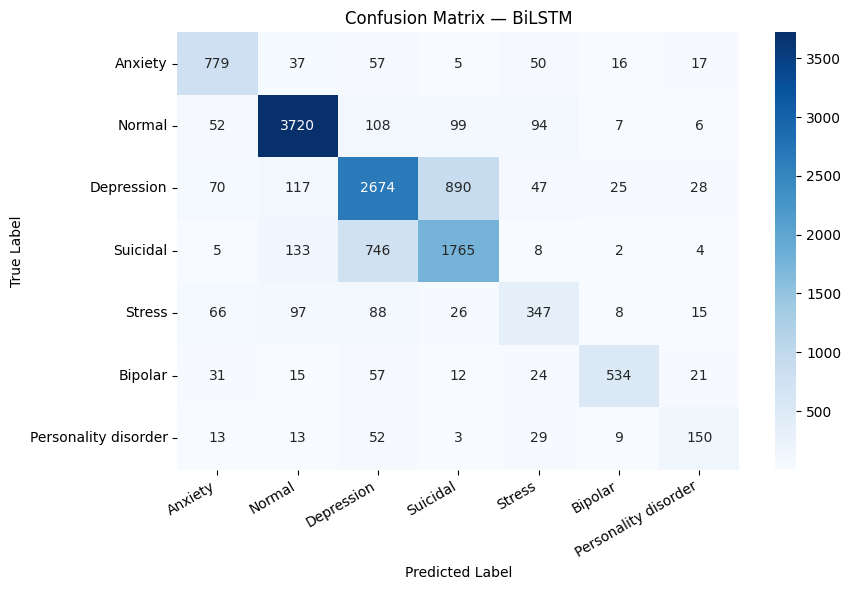

In [72]:
plot_cm(y_test, y_pred_bilstm, 'Confusion Matrix — BiLSTM')

The BiLSTM handles the minority classes better than Naïve Bayes, particularly Stress and Personality Disorder.

In [73]:
df_list_metrics.append(return_metrics('BiLSTM', y_pred_bilstm, y_test))

### BiLSTM Refinement — Embedding Dimension

comparing embedded dimension 64 vs the 128 model above to see which performs better. This is a form of hyperparameter tuning.

In [74]:
# Training a smaller version with embed_dim=64 and compare
bilstm_small = build_bilstm(VOCAB_SIZE, 64, MAX_LEN, num_classes)
bilstm_small.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])

bilstm_small.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=0
)

y_pred_small = np.argmax(bilstm_small.predict(X_test_pad, verbose=0), axis=1)
f1_small = f1_score(y_test, y_pred_small, average='weighted')
f1_128   = f1_score(y_test, y_pred_bilstm, average='weighted')

print(f'BiLSTM embed_dim=64  — Weighted F1: {f1_small:.4f}')
print(f'BiLSTM embed_dim=128 — Weighted F1: {f1_128:.4f}')

BiLSTM embed_dim=64  — Weighted F1: 0.7548
BiLSTM embed_dim=128 — Weighted F1: 0.7567


The embed_dim=128 model performs better and is retained as the final BiLSTM.

## Deep Learning Model 2 — Transformer



In [75]:
class TransformerBlock(layers.Layer):
  
    
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, **kwargs):
        super(TransformerBlock, self).__init__(**kwargs)
        self.att        = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn        = keras.Sequential([
            layers.Dense(ff_dim, activation='relu'),
            layers.Dense(embed_dim)
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1   = layers.Dropout(rate)
        self.dropout2   = layers.Dropout(rate)

    def call(self, inputs, training=None):
        # Self-attention: each token attends to all other tokens
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        # Residual connection + layer norm
        out1 = self.layernorm1(inputs + attn_output)
        # Feed-forward network
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

In [76]:
class TokenAndPositionEmbedding(layers.Layer):

    def __init__(self, maxlen, vocab_size, embed_dim, **kwargs):
        super(TokenAndPositionEmbedding, self).__init__(**kwargs)
        self.token_emb = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb   = layers.Embedding(input_dim=maxlen,     output_dim=embed_dim)

    def call(self, x):
        maxlen    = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)   # position embedding
        x         = self.token_emb(x)         # token embedding
        return x + positions                  # combine by addition

In [77]:
def build_transformer(vocab_size, max_len, embed_dim, num_heads, ff_dim,
                       num_classes, dropout=0.1):
   
    inputs = layers.Input(shape=(max_len,), name='input_ids')

    # Embed tokens and positions together
    x = TokenAndPositionEmbedding(max_len, vocab_size, embed_dim)(inputs)

    # Stack two Transformer blocks for greater representational depth
    x = TransformerBlock(embed_dim, num_heads, ff_dim, rate=dropout)(x)
    x = TransformerBlock(embed_dim, num_heads, ff_dim, rate=dropout)(x)

    # Pool across the sequence dimension to get a fixed-size representation
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(dropout)(x)

    # Softmax output
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs, name='Transformer')

In [78]:
transformer_model = build_transformer(
    vocab_size=VOCAB_SIZE,
    max_len=MAX_LEN,
    embed_dim=64,
    num_heads=8,
    ff_dim=128,
    num_classes=num_classes
)
transformer_model.summary()

Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_ids (InputLayer)               │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ token_and_position_embedding         │ (None, 200, 64)             │       1,932,800 │
│ (TokenAndPositionEmbedding)          │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_block (TransformerBlock) │ (None, 200, 64)             │         149,504 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ transformer_block_1                  │ (None, 200, 64)             │         149,504 │
│ (TransformerBlock)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 7)                   │             455 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,236,423 (8.53 MB)

 Trainable params: 2,236,423 (8.53 MB)

 Non-trainable params: 0 (0.00 B)

In [79]:
transformer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [80]:
callbacks_transformer = [
    EarlyStopping(patience=3, restore_best_weights=True, monitor='val_accuracy'),
    ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

history_transformer = transformer_model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks_transformer,
    verbose=1
)

Epoch 1/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 573s 1s/step - accuracy: 0.6441 - loss: 0.9200 - val_accuracy: 0.7497 - val_loss: 0.6719 - learning_rate: 5.0000e-04
Epoch 2/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 539s 969ms/step - accuracy: 0.7808 - loss: 0.5750 - val_accuracy: 0.7801 - val_loss: 0.5816 - learning_rate: 5.0000e-04
Epoch 3/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 523s 941ms/step - accuracy: 0.8433 - loss: 0.4146 - val_accuracy: 0.7669 - val_loss: 0.6183 - learning_rate: 5.0000e-04
Epoch 4/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 0s 911ms/step - accuracy: 0.8986 - loss: 0.2843
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
556/556 ━━━━━━━━━━━━━━━━━━━━ 524s 942ms/step - accuracy: 0.8948 - loss: 0.2915 - val_accuracy: 0.7512 - val_loss: 0.7627 - learning_rate: 5.0000e-04
Epoch 5/10
556/556 ━━━━━━━━━━━━━━━━━━━━ 543s 977ms/step - accuracy: 0.9374 - loss: 0.1769 - val_accuracy: 0.7570 - val_loss: 0.8430 - learning_rate: 2.5000e-04


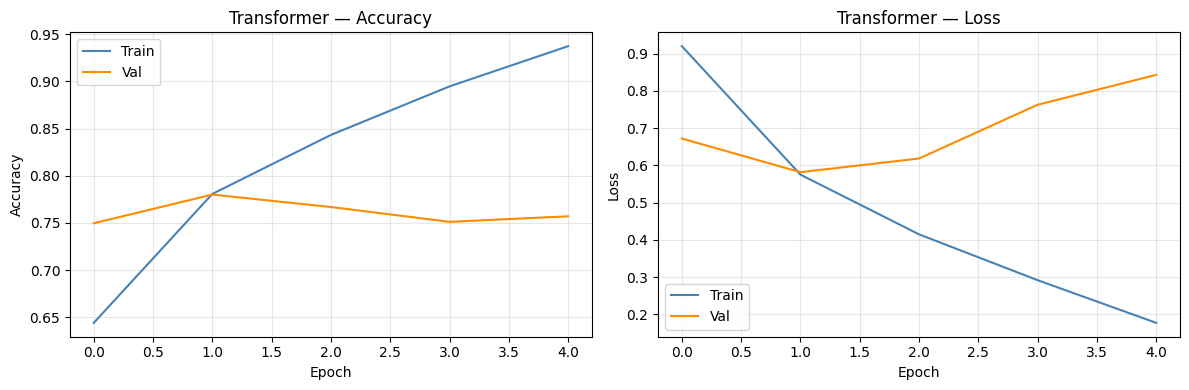

In [81]:
plot_history(history_transformer, 'Transformer')

In [82]:
y_proba_transformer = transformer_model.predict(X_test_pad, verbose=0)
y_pred_transformer  = np.argmax(y_proba_transformer, axis=1)

In [83]:
print(classification_report(y_test, y_pred_transformer,
                             target_names=[int_to_label[i] for i in range(num_classes)]))

                      precision    recall  f1-score   support

             Anxiety       0.74      0.86      0.79       961
              Normal       0.91      0.92      0.91      4086
          Depression       0.71      0.75      0.73      3851
            Suicidal       0.68      0.61      0.64      2663
              Stress       0.61      0.50      0.55       647
             Bipolar       0.74      0.83      0.78       694
Personality disorder       0.86      0.49      0.62       269

            accuracy                           0.77     13171
           macro avg       0.75      0.71      0.72     13171
        weighted avg       0.77      0.77      0.77     13171



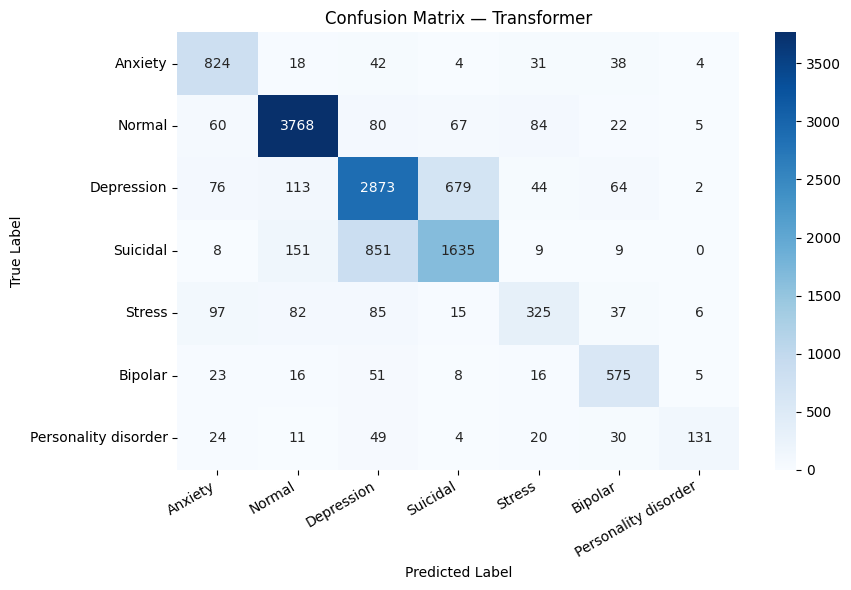

In [84]:
plot_cm(y_test, y_pred_transformer, 'Confusion Matrix — Transformer')

In [85]:
df_list_metrics.append(return_metrics('Transformer', y_pred_transformer, y_test))

### Transformer Refinement — Number of Attention Heads



In [86]:
# Retrain with 4 heads and compare against the 8-head model above
transformer_4h = build_transformer(VOCAB_SIZE, MAX_LEN, 64, 4, 128, num_classes)
transformer_4h.compile(optimizer='adam',
                       loss='sparse_categorical_crossentropy',
                       metrics=['accuracy'])

transformer_4h.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=0
)

y_pred_4h = np.argmax(transformer_4h.predict(X_test_pad, verbose=0), axis=1)
f1_4h = f1_score(y_test, y_pred_4h, average='weighted')
f1_8h = f1_score(y_test, y_pred_transformer, average='weighted')

print(f'Transformer 4 heads — Weighted F1: {f1_4h:.4f}')
print(f'Transformer 8 heads — Weighted F1: {f1_8h:.4f}')

Transformer 4 heads — Weighted F1: 0.7579
Transformer 8 heads — Weighted F1: 0.7661


The 8-head model performs better and is kept as the final Transformer.

## Evaluation

combining  all model metrics and compare them across accuracy, weighted F1, and macro ROC-AUC.

Compute ROC-AUC for all models using one-vs-rest binarisation

In [87]:
def compute_roc_auc(y_true, y_proba, n):
   
    y_bin = label_binarize(y_true, classes=list(range(n)))
    return roc_auc_score(y_bin, y_proba, multi_class='ovr', average='macro')

In [88]:
# Get class probabilities for the ML models
y_proba_nb = nb_gs.predict_proba(X_test)
y_proba_lr = lr_gs.predict_proba(X_test)

roc_nb = compute_roc_auc(y_test, y_proba_nb,  num_classes)
roc_lr = compute_roc_auc(y_test, y_proba_lr,  num_classes)
roc_bi = compute_roc_auc(y_test, y_proba_bilstm,       num_classes)
roc_tr = compute_roc_auc(y_test, y_proba_transformer,  num_classes)

print(f'Naïve Bayes         ROC-AUC: {roc_nb:.4f}')
print(f'Logistic Regression ROC-AUC: {roc_lr:.4f}')
print(f'BiLSTM              ROC-AUC: {roc_bi:.4f}')
print(f'Transformer         ROC-AUC: {roc_tr:.4f}')

Naïve Bayes         ROC-AUC: 0.9308
Logistic Regression ROC-AUC: 0.9499
BiLSTM              ROC-AUC: 0.9452
Transformer         ROC-AUC: 0.9573


In [89]:
results_table = pd.concat(df_list_metrics).reset_index(drop=True)

# Add ROC-AUC column
results_table['Macro ROC-AUC'] = ['—', f'{roc_nb:.4f}', f'{roc_lr:.4f}',
                                   f'{roc_bi:.4f}', f'{roc_tr:.4f}']
results_table

,Model,Accuracy,Weighted F1,Macro ROC-AUC
0,Majority Baseline,0.3102,0.1469,—
1,Naïve Bayes (tuned),0.6976,0.6970,0.9308
2,Logistic Regression (tuned),0.7558,0.7553,0.9499
3,BiLSTM,0.7569,0.7567,0.9452
4,Transformer,0.7692,0.7661,0.9573


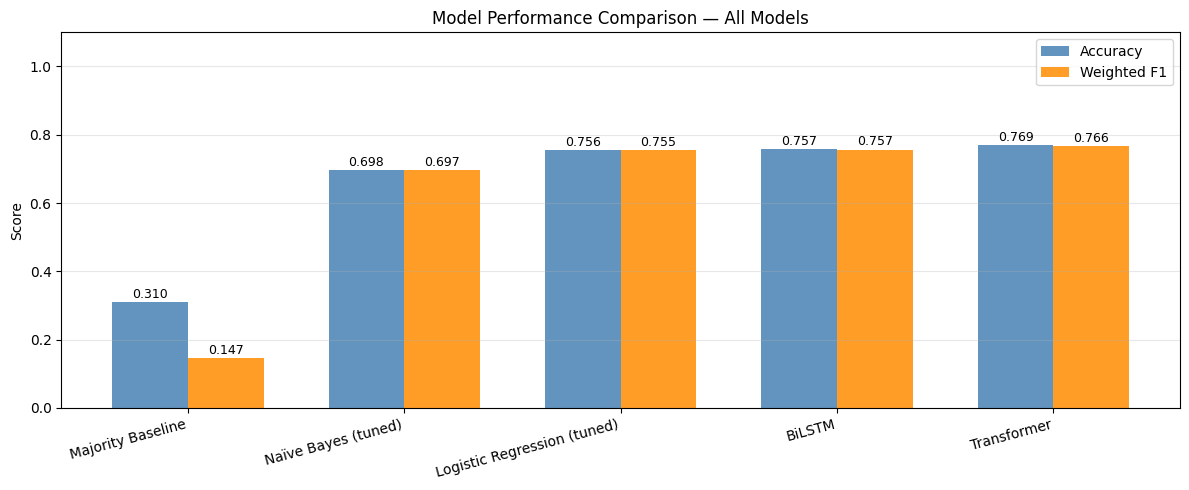

In [90]:
# visualising the accuracy and weighted F1 side by side for easy comparison
models   = results_table['Model'].tolist()
acc_vals = results_table['Accuracy'].astype(float).tolist()
f1_vals  = results_table['Weighted F1'].astype(float).tolist()

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, acc_vals, width, label='Accuracy',    color='steelblue',  alpha=0.85)
bars2 = ax.bar(x + width/2, f1_vals,  width, label='Weighted F1', color='darkorange', alpha=0.85)

# Annotate bars with their values
for bar in list(bars1) + list(bars2):
    ax.annotate(f'{bar.get_height():.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)

ax.set_title('Model Performance Comparison — All Models')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

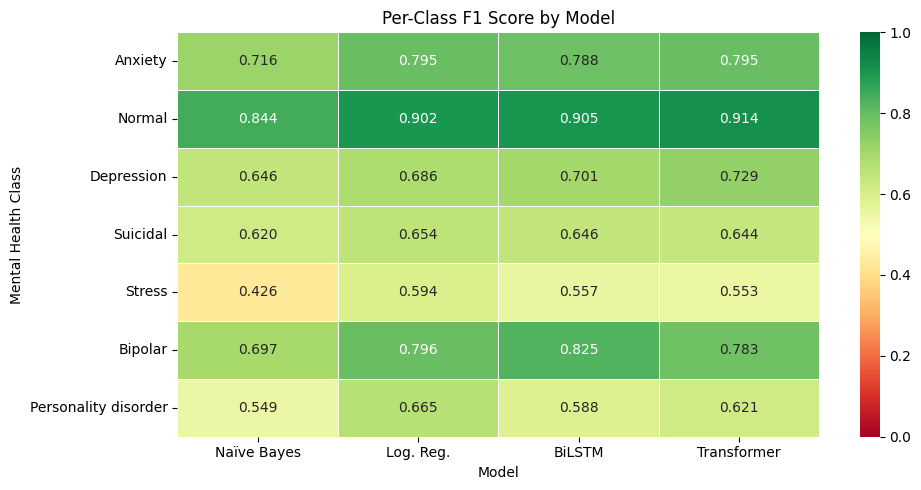

In [91]:
# Per-class F1 heatmap
pc_f1 = pd.DataFrame({
    'Naïve Bayes'   : f1_score(y_test, y_pred_nb_tuned,   average=None,
                                labels=list(range(num_classes))),
    'Log. Reg.'     : f1_score(y_test, y_pred_lr_tuned,   average=None,
                                labels=list(range(num_classes))),
    'BiLSTM'        : f1_score(y_test, y_pred_bilstm,      average=None,
                                labels=list(range(num_classes))),
    'Transformer'   : f1_score(y_test, y_pred_transformer, average=None,
                                labels=list(range(num_classes))),
}, index=[int_to_label[i] for i in range(num_classes)])

plt.figure(figsize=(10, 5))
sns.heatmap(pc_f1, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1, linewidths=0.5)
plt.title('Per-Class F1 Score by Model')
plt.ylabel('Mental Health Class')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

## Predicting New Statements

In [92]:
def predict_statement(text, model_choice='transformer'):
    """
    Predict the mental health status of a new raw text statement.

    Parameters
    ----------
    text         : str — raw input statement
    model_choice : str — one of 'nb', 'lr', 'bilstm', 'transformer'

    Returns
    -------
    dict — predicted label and confidence score
    """
    # Apply the same preprocessing as training
    cleaned = re.sub(r'https?://\S+|www\.\S+|<.*?>', '', text.lower())
    cleaned = re.sub(r'[^\w\s]', '', cleaned)
    cleaned = re.sub(r'\d+', '', cleaned)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()

    stop_words = set(stopwords.words('english'))
    cleaned = ' '.join(w for w in cleaned.split() if w not in stop_words)
    processed = ' '.join(token.lemma_ for token in nlp(cleaned))

    if model_choice in ('nb', 'lr'):
        pipe     = nb_gs if model_choice == 'nb' else lr_gs
        pred_idx = pipe.predict([processed])[0]
        proba    = pipe.predict_proba([processed])[0]
    else:
        seq     = tokenizer_dl.texts_to_sequences([processed])
        seq_pad = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')
        m       = bilstm_model if model_choice == 'bilstm' else transformer_model
        proba   = m.predict(seq_pad, verbose=0)[0]
        pred_idx = int(np.argmax(proba))

    return {'predicted': int_to_label[pred_idx],
            'confidence': f'{float(np.max(proba)):.2%}'}

In [93]:
# Test the prediction function on some example statements
test_statements = [
    "I haven't been able to sleep and I keep crying for no reason.",
    "I feel great today, went for a run and had a lovely meal with friends.",
    "I keep switching between feeling on top of the world and completely hopeless.",
    "The thoughts won't stop. I just want everything to end.",
    "I'm overwhelmed with work deadlines and can't seem to calm down."
]

for stmt in test_statements:
    result = predict_statement(stmt, model_choice='transformer')
    print(f'Statement  : {stmt}')
    print(f'Prediction : {result["predicted"]}  ({result["confidence"]})')
    print()

Statement  : I haven't been able to sleep and I keep crying for no reason.
Prediction : Normal  (95.49%)

Statement  : I feel great today, went for a run and had a lovely meal with friends.
Prediction : Normal  (92.98%)

Statement  : I keep switching between feeling on top of the world and completely hopeless.
Prediction : Depression  (60.18%)

Statement  : The thoughts won't stop. I just want everything to end.
Prediction : Normal  (45.65%)

Statement  : I'm overwhelmed with work deadlines and can't seem to calm down.
Prediction : Stress  (41.26%)

